### 1. Load and Explore the Dataset
We will read the dataset from `/content/telecom_churn.csv` and inspect its shape and first few rows.

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
dfp = '/content/telecom_churn.csv'
try:
    df = pd.read_csv(dfp)
    print("Dataset loaded successfully.")
    display(df.head())
    print(df.info())
except Exception as e:
    print(f"Error loading file: {e}. Please ensure the file exists at {dfp}.")

Dataset loaded successfully.


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   

In [ ]:
# Show all columns in pandas display so nothing gets hidden/truncated
pd.set_option('display.max_columns', None)

# Specifically display the evening-related columns to verify they exist
eve_cols = [col for col in df.columns if 'eve' in col]
display(df[eve_cols].head())

### 2. Preprocess Data and Train/Test Split
We need to encode categorical variables, handle any missing values, and split our dataset into features (`X`) and target labels (`y`). Please make sure to adjust the `target_column` name below if it differs in your dataset.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify target column (assuming 'Churn' or similar based on telecom data)
target_column = None
possible_targets = ['churn', 'Churn', 'class', 'Class', 'target']
for col in possible_targets:
    if col in df.columns:
        target_column = col
        break

if target_column is None:
    # Fallback to the last column if no matching name found
    target_column = df.columns[-1]

print(f"Using '{target_column}' as the target column.")

X = df.drop(columns=[target_column])
y = df[target_column]

# If target is categorical string, convert to numeric label
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# Identify numeric and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessing pipelines
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Using 'churn' as the target column.
Training set shape: (2666, 20)
Testing set shape: (667, 20)


### 3. Model Training & Evaluation
We will implement, train, and evaluate **Logistic Regression**, **Decision Tree Classifier**, and **Random Forest Classifier** models.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

# Configure models with user-specified hyperparameters
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
}

for name, model in models.items():
    # Combine preprocessing and model
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    print(f"=== {name} Performance ===")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    try:
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
    except Exception:
        pass
    print(classification_report(y_test, y_pred))
    print("-" * 50)

=== Logistic Regression Performance ===
Accuracy: 0.8591
ROC AUC Score: 0.8094
              precision    recall  f1-score   support

       False       0.88      0.96      0.92       570
        True       0.53      0.25      0.34        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.63       667
weighted avg       0.83      0.86      0.84       667

--------------------------------------------------
=== Decision Tree Performance ===
Accuracy: 0.9175
ROC AUC Score: 0.8043
              precision    recall  f1-score   support

       False       0.94      0.96      0.95       570
        True       0.76      0.64      0.69        97

    accuracy                           0.92       667
   macro avg       0.85      0.80      0.82       667
weighted avg       0.91      0.92      0.91       667

--------------------------------------------------
=== Random Forest Performance ===
Accuracy: 0.8546
ROC AUC Score: 0.8491
              preci

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### 4. Comparative Summary of Model Performance
We will extract the metrics (Accuracy, Precision, Recall, and F1-Score) for the positive class (Churn = True) from each model and display them in a comparison table.

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

results_dict = {}

for name, model in models.items():
    # Re-create pipeline
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Get predictions
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', pos_label=True)

    # Store results with model name as key for transposing
    results_dict[name] = {
        "Accuracy": f"{accuracy:.4f}",
        "Precision": f"{precision:.4f}",
        "Recall": f"{recall:.4f}",
        "F-1 Score": f"{f1:.4f}"
    }

# Create comparative summary table with models on columns and metrics on rows
summary_df = pd.DataFrame(results_dict)
summary_df.index.name = "Metric"
summary_df = summary_df.reset_index()
display(summary_df)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.8591,0.9175,0.8546
1,Precision,0.5333,0.7561,0.0000
2,Recall,0.2474,0.6392,0.0000
3,F-1 Score,0.3380,0.6927,0.0000


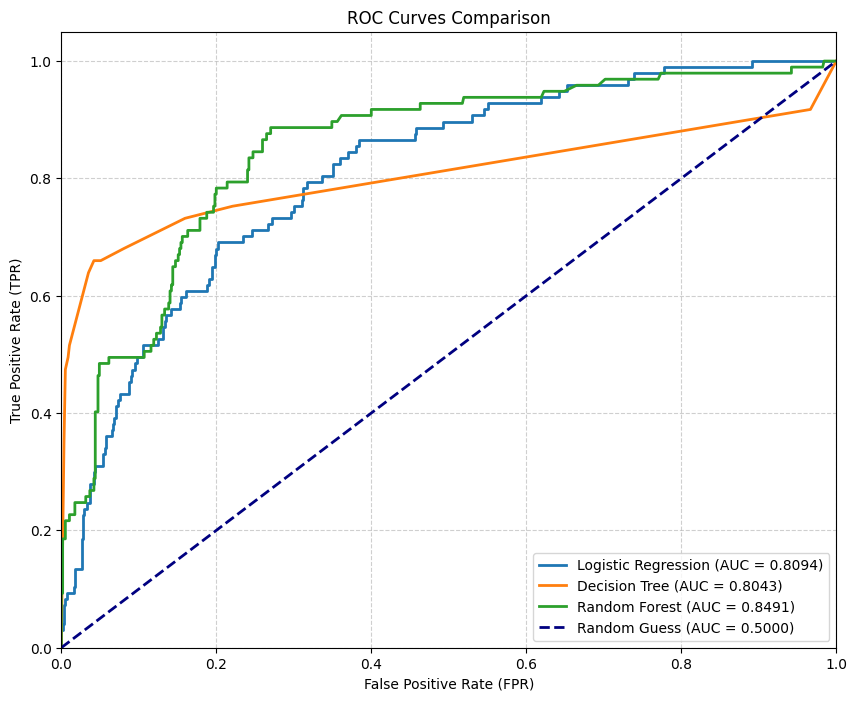

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# Loop through each model to calculate and plot its ROC curve
for name, model in models.items():
    # Re-create pipeline to ensure preprocessing is applied
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Get prediction probabilities for the positive class
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Compute ROC curve and ROC area
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    # Plot individual model ROC curve
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', lw=2)

# Plot the diagonal baseline representing a random classifier
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.5000)')

# Customize the plot labels and titles
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves Comparison')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 5. Confusion Matrices for All Models
We will plot the confusion matrices to see how many true positives, true negatives, false positives, and false negatives each model produces on the test set.

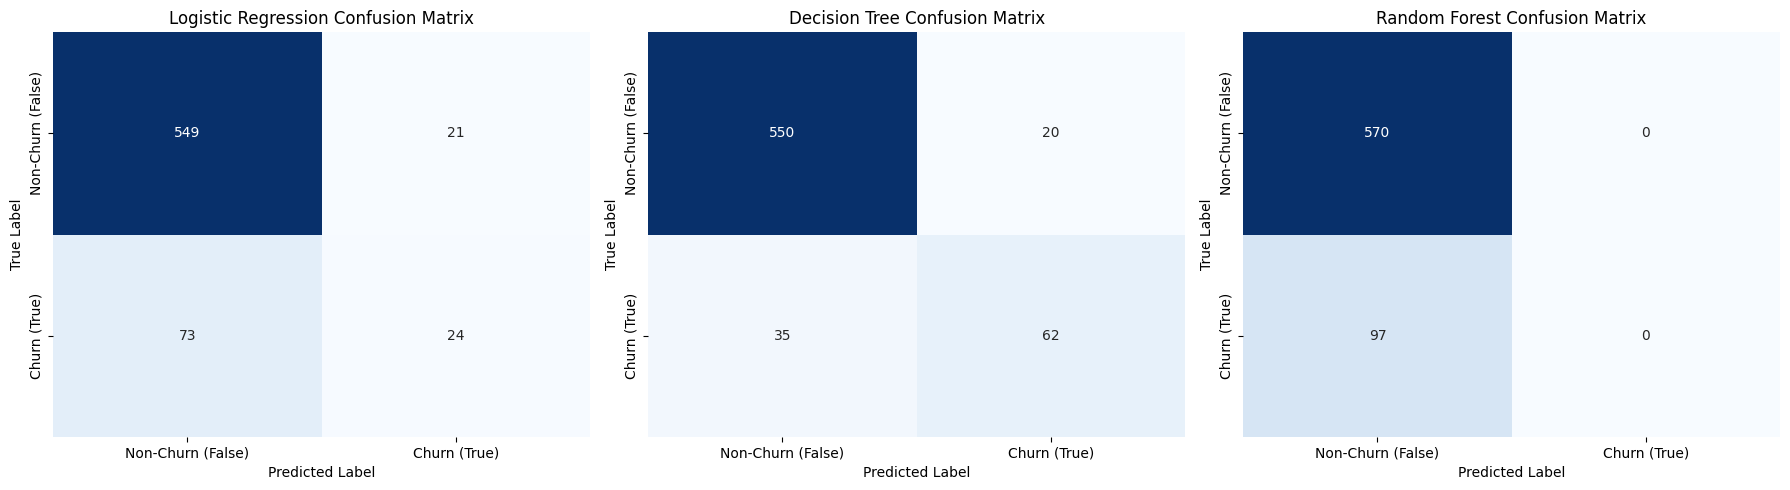

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Set up a grid of subplots for the three models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    # Re-create pipeline to ensure preprocessing is applied
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])

    # Predict class labels
    y_pred = pipeline.predict(X_test)

    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot confusion matrix heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Non-Churn (False)', 'Churn (True)'],
                yticklabels=['Non-Churn (False)', 'Churn (True)'])

    ax.set_title(f'{name} Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()